<a href="https://colab.research.google.com/github/lewinskie254/timeseries-youtube/blob/main/Lecture_4_Timeseries_Analysis_AutoregressiveModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from statsmodels.tsa.stattools import adfuller
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf #added the pacf plot
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv("https://raw.githubusercontent.com/marcopeix/TimeSeriesForecastingInPython/master/data/foot_traffic.csv")

In [9]:
df.head()

,foot_traffic
0,500.496714
1,500.522366
2,501.426876
3,503.295990
4,504.132695


<Axes: >

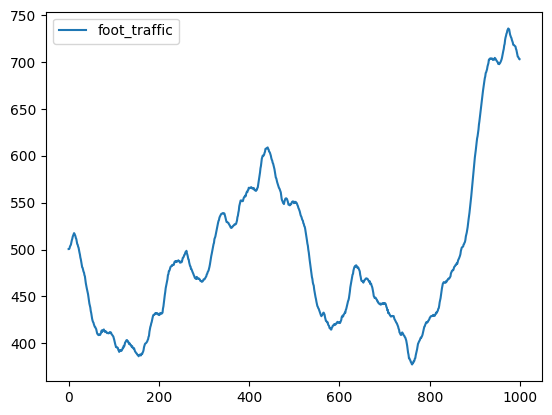

In [10]:
df.plot()

In [11]:
#evaluate if the data is stationary
result = adfuller(df["foot_traffic"])
print('ADF Statistic: %f' % result[0])
print('p-value: %f' % result[1])

ADF Statistic: -1.175889
p-value: 0.683881


/tmp/ipykernel_1760/1231579332.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df["foot_traffic"])


In [12]:
#not stationary so let's difference the data

df_diff = df.diff()

<Axes: >

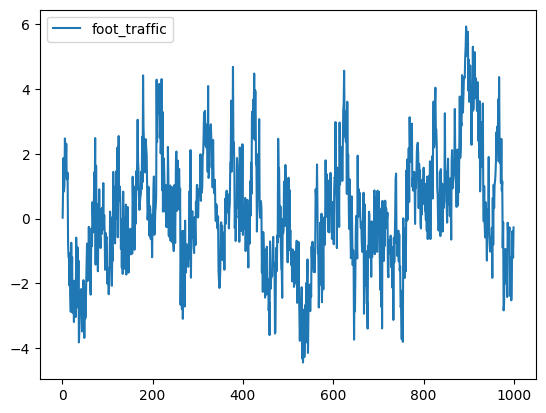

In [13]:
df_diff.plot()

In [17]:
#evaluate if the differenced data is stationary
result_2 = adfuller(df_diff[1:])
print('ADF Statistic: %f' % result_2[0])
print('p-value: %f' % result_2[1])

ADF Statistic: -5.268231
p-value: 0.000006


/tmp/ipykernel_1760/25120571.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_2 = adfuller(df_diff[1:])


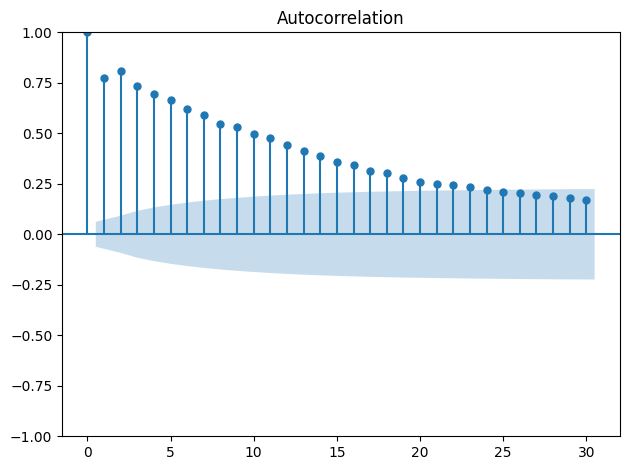

In [19]:
#now that the data is stationary, let's evalaute if its a moving average process
plot_acf(df_diff[1:])
plt.tight_layout()

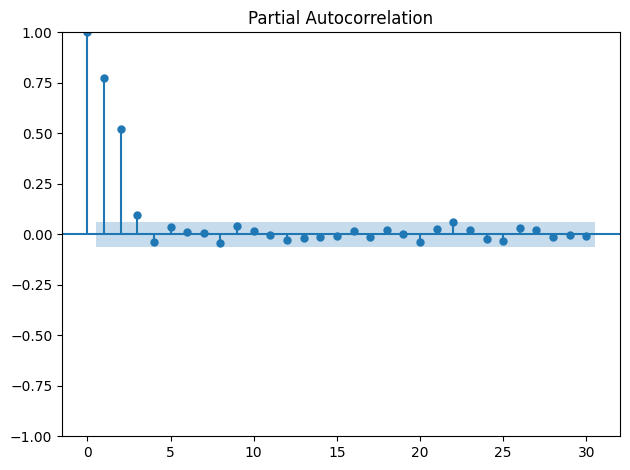

In [20]:
# since there is no abrupt change in the autocorrelation, then this is not a moving average process
# next step is to plot the pacf function of the differenced data

plot_pacf(df_diff[1:])
plt.tight_layout()

In [ ]:
#now we have the value of p: its 3

In [27]:
from statsmodels.tsa.statespace.sarimax import SARIMAX


def rolling_forecast(df: pd.DataFrame, train_len: int, horizon: int,window: int, method: str, p: int) -> list:
  total_len = train_len + horizon

  #naive method that uses the last timesteps value as the current prediction
  if method == 'last':

    # a list to populate the last timestep preditions
    pred_last_value = []

    #scan through the entire dataset, from the initial training data, and then extend the training data until we get to the final result
    for i in range(train_len, total_len, window):

      #use the previous timestep value as the predictions for this timestep and for all batches in this prediction window
      last_value = df[:i].iloc[-1].values[0]

      #populate the last timestep predictions
      pred_last_value.extend(last_value for _ in range(window))
    return pred_last_value

  #if the method is an AR method
  elif method == 'AR':

      #create a list to populate predictions
      pred_AR = []
      for i in range(train_len, total_len, window):
        #pass the data up to the current timestep to our autoregressive model
        #remember its ARIMA AR(p), I(d), MA(q), so let's pass p as the first elemenet in the model
        model = SARIMAX(df[:i], order=(p,0,0))

        #fit the model
        res = model.fit(disp=False)

        #fetch predictions
        predictions = res.get_prediction(0, i + window - 1)

        #get the mean predictions
        oos_pred = predictions.predicted_mean.iloc[-window:]

        #populate the predictions to the list
        pred_AR.extend(oos_pred)

      #return the list of predictions
      return pred_AR

In [25]:
train = df_diff[:int(0.8 * len(df_diff))] # use the slicing method to preserve the order
test = train = df_diff[int(0.8 * len(df_diff)):]

In [37]:
#test data to evaluate how well our model is doing
pred_df = test.copy()

#set the details for the model, we will make predictions in batches of 2 (window)
TRAIN_LEN = len(train)
HORIZON = len(test)
WINDOW = 1
P = 3 #AR(P), where our P from the PACF plot is 3

pred_last_value = rolling_forecast(df_diff, TRAIN_LEN, HORIZON, WINDOW,'last', P)
pred_AR = rolling_forecast(df_diff, TRAIN_LEN, HORIZON, WINDOW, 'AR', P)

In [38]:
#populate the predictions dataset for easier analysis

pred_df['pred_last_value'] = pred_last_value
pred_df['pred_AR'] = pred_AR
pred_df.head()

,foot_traffic,pred_last_value,pred_AR
800,1.568943,-1.193335,-0.397584
801,0.449790,-0.126753,-0.607348
802,1.086329,-0.091575,-0.266443
803,0.230934,0.905922,0.189838
804,0.216362,1.298096,0.762915


In [39]:
# Evaluate the model

from sklearn.metrics import mean_squared_error

mse_last = mean_squared_error(pred_df['foot_traffic'],pred_df['pred_last_value'])
mse_AR = mean_squared_error(pred_df['foot_traffic'],pred_df['pred_AR'])
print(mse_last, mse_AR)

6.516498175285369 5.933614543998692


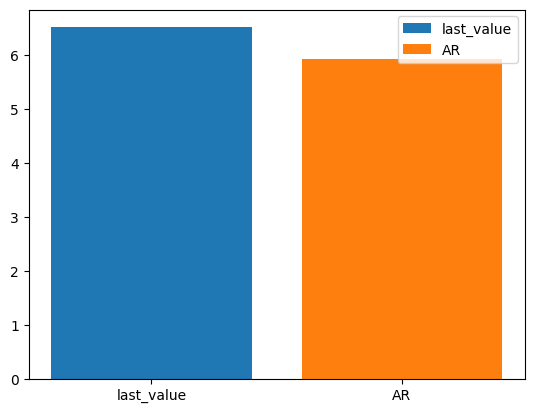

In [40]:
#plot the metrics

plt.bar('last_value', mse_last, label='last_value')
plt.bar('AR', mse_AR, label='AR')
plt.legend()

In [41]:
#create a new dataframe for the series
df['pred_foot_traffic'] = pd.Series()

#To integrate the differenced data, we simply just cumulative sum from the last item in the train set
df.loc[TRAIN_LEN:, 'pred_foot_traffic'] = (df['foot_traffic'].iloc[TRAIN_LEN]+ pred_df['pred_AR'].cumsum())

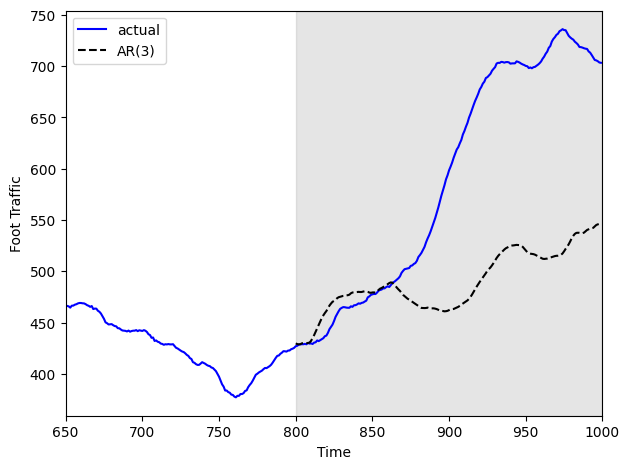

In [45]:
#plot the predictions and compare them to the actual values.
fig, ax = plt.subplots()
ax.plot(df['foot_traffic'], 'b-', label='actual')
ax.plot(df['pred_foot_traffic'], 'k--', label='AR(3)')
ax.legend(loc=2)
ax.set_xlabel('Time')
ax.set_ylabel('Foot Traffic')
ax.axvspan(800, 1000, color='#808080', alpha=0.2)

ax.set_xlim(650, 1000)
plt.tight_layout()